In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score
from pathlib import Path
import json
import sys
import joblib
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold


# 1. Data Understanding

## 1.1 Loading and Inspecting the Clean Datasets

Before performing exploratory data analysis, we first inspect the cleaned datasets to understand their structure and contents.

For each dataset, we will examine:
- The number of rows and columns.
- The column names and data types.
- A sample of the records.
- The missing values in each column.
- The number of duplicate rows.

The goal is to understand what information is available in each table before deciding which analyses and churn-related features can be derived from it.

In [5]:
transactions_clean = pd.read_csv("/kaggle/input/datasets/mohamed2gamal5/h-and-m-fashion-data-preprocessed/transactions_clean.csv")
customers_clean = pd.read_csv("/kaggle/input/datasets/mohamed2gamal5/h-and-m-fashion-data-preprocessed/customers_clean.csv")
articles_clean = pd.read_csv("/kaggle/input/datasets/mohamed2gamal5/h-and-m-fashion-data-preprocessed/articles_clean.csv")

In [6]:
datasets = {
    "Transactions": transactions_clean,
    "Customers": customers_clean,
    "Articles": articles_clean
}

for name, df in datasets.items():
    print(f"\n{'=' * 60}")
    print(f"{name}")
    print(f"{'=' * 60}")
    print(f"Shape: {df.shape}")
    print("\nColumns and data types:")
    print(df.dtypes)
    print("\nFirst 5 rows:")
    display(df.head())
    print("\nMissing values:")
    display(df.isnull().sum().to_frame("Missing Values"))
    print(f"\nDuplicate rows: {df.duplicated().sum()}")


Transactions
Shape: (8837417, 5)

Columns and data types:
t_dat                object
customer_id          object
article_id            int64
price               float64
sales_channel_id      int64
dtype: object

First 5 rows:


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,0008968c0d451dbc5a9968da03196fe20051965edde741...,529841001,0.020322,2
1,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,685687002,0.016932,2
2,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,685687002,0.016932,2
3,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,680912009,0.011847,2
4,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,680912009,0.011847,2



Missing values:


,Missing Values
t_dat,0
customer_id,0
article_id,0
price,0
sales_channel_id,0



Duplicate rows: 828665

Customers
Shape: (1076441, 8)

Columns and data types:
customer_id                object
FN                          int64
Active                      int64
club_member_status         object
fashion_news_frequency     object
age                       float64
postal_code                object
age_was_missing             int64
dtype: object

First 5 rows:


...


Duplicate rows: 0

Articles
Shape: (30000, 26)

Columns and data types:
article_id                       int64
product_code                     int64
prod_name                       object
product_type_no                  int64
product_type_name               object
product_group_name              object
graphical_appearance_no          int64
graphical_appearance_name       object
colour_group_code                int64
colour_group_name               object
perceived_colour_value_id        int64
perceived_colour_value_name     object
perceived_colour_master_id       int64
perceived_colour_master_name    object
department_no                    int64
department_name                 object
index_code                      object
index_name                      object
index_group_no                   int64
index_group_name                object
section_no                       int64
section_name                    object
garment_group_no                 int64
garment_group_name            

,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,...,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc,image_path
0,667999002,667999,Ledger set,255,T-shirt,Garment Upper body,1010014,Placement print,93,Dark Green,...,I,Children Sizes 134-170,4,Baby/Children,47,Young Boy,1005,Jersey Fancy,T-shirt in cotton jersey and joggers in sweats...,/kaggle/input/competitions/h-and-m-personalize...
1,868956002,868956,Drogo tee,258,Blouse,Garment Upper body,1010001,All over pattern,92,Green,...,D,Divided,2,Divided,50,Divided Projects,1010,Blouses,"Blouse in a patterned, lightly crêped viscose ...",/kaggle/input/competitions/h-and-m-personalize...
2,611584006,611584,Piper top,253,Vest top,Garment Upper body,1010016,Solid,73,Dark Blue,...,D,Divided,2,Divided,50,Divided Projects,1005,Jersey Fancy,Short top in soft jersey with narrow shoulder ...,/kaggle/input/competitions/h-and-m-personalize...
3,659460002,659460,Joel light down jacket,262,Jacket,Garment Upper body,1010016,Solid,12,Light Beige,...,A,Ladieswear,1,Ladieswear,19,Womens Jackets,1007,Outdoor,"Fitted, quilted, lightweight jacket with a sma...",/kaggle/input/competitions/h-and-m-personalize...
4,640801001,640801,Daisy price hood,308,Hoodie,Garment Upper body,1010014,Placement print,51,Light Pink,...,H,Children Sizes 92-140,4,Baby/Children,76,Kids Girl,1005,Jersey Fancy,Hooded jacket in sweatshirt fabric with a prin...,/kaggle/input/competitions/h-and-m-personalize...



Missing values:


,Missing Values
article_id,0
product_code,0
prod_name,0
product_type_no,0
product_type_name,0
product_group_name,0
graphical_appearance_no,0
graphical_appearance_name,0
colour_group_code,0
colour_group_name,0



Duplicate rows: 0


In [7]:
transactions_clean = transactions_clean.drop_duplicates().reset_index(drop=True)

print("Shape after removing exact duplicates:", transactions_clean.shape)
print("Remaining duplicate rows:", transactions_clean.duplicated().sum())

Shape after removing exact duplicates: (8008752, 5)
Remaining duplicate rows: 0


# 2. Understanding Transaction Behavior

## 2.1 Transaction Time Coverage

Before defining customer churn, we need to understand the time span and activity patterns captured by the transaction dataset.

We will examine the overall transaction period, yearly and monthly activity, and the number of distinct customers purchasing over time.

This helps us determine whether the dataset provides enough historical information to distinguish normal gaps between purchases from potentially meaningful customer inactivity.

In [8]:
transactions_clean["t_dat"] = pd.to_datetime(
    transactions_clean["t_dat"],
    errors="coerce"
)

print("First transaction date:", transactions_clean["t_dat"].min())
print("Last transaction date:", transactions_clean["t_dat"].max())
print("Number of transaction dates:", transactions_clean["t_dat"].nunique())

yearly_activity = (
    transactions_clean
    .groupby(transactions_clean["t_dat"].dt.year)
    .agg(
        transaction_rows=("customer_id", "size"),
        unique_customers=("customer_id", "nunique"),
        unique_articles=("article_id", "nunique")
    )
)

display(yearly_activity)

monthly_activity = (
    transactions_clean
    .groupby(transactions_clean["t_dat"].dt.to_period("M"))
    .agg(
        transaction_rows=("customer_id", "size"),
        unique_customers=("customer_id", "nunique")
    )
)

display(monthly_activity)

First transaction date: 2018-09-20 00:00:00
Last transaction date: 2020-09-22 00:00:00
Number of transaction dates: 734


,transaction_rows,unique_customers,unique_articles
t_dat,,,
2018,1159467,406741,12002
2019,4177956,764540,20234
2020,2671329,646011,17373


,transaction_rows,unique_customers
t_dat,,
2018-09,159157,84369
2018-10,363293,171948
2018-11,336692,166945
2018-12,300325,151867
2019-01,311225,149198
2019-02,298119,145341
2019-03,336933,155181
2019-04,382666,170530
2019-05,404287,176745


## 2.2 Customer Purchase Frequency and Recency

Customer churn should be defined using observed purchasing behavior rather than an arbitrary inactivity period.

In this section, we will analyze:
- The number of distinct purchase dates per customer.
- The distribution of customers by purchase frequency.
- The time gaps between consecutive purchase dates for each customer.
- The distribution of each customer's most recent purchase date.

These patterns will help us understand typical repeat-purchase behavior and establish evidence for selecting an inactivity threshold for churn labeling.

In [9]:
customer_purchase_days = (
    transactions_clean
    .groupby("customer_id")["t_dat"]
    .nunique()
    .rename("purchase_days")
)

frequency_summary = pd.DataFrame({
    "Metric": [
        "Customers with at least one purchase",
        "Customers with one purchase day",
        "Customers with multiple purchase days",
        "Percentage with one purchase day",
        "Percentage with multiple purchase days"
    ],
    "Value": [
        customer_purchase_days.size,
        (customer_purchase_days == 1).sum(),
        (customer_purchase_days > 1).sum(),
        round((customer_purchase_days == 1).mean() * 100, 2),
        round((customer_purchase_days > 1).mean() * 100, 2)
    ]
})

display(frequency_summary)

display(
    customer_purchase_days
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame("Purchase days")
)

,Metric,Value
0,Customers with at least one purchase,1076441.00
1,Customers with one purchase day,392019.00
2,Customers with multiple purchase days,684422.00
3,Percentage with one purchase day,36.42
4,Percentage with multiple purchase days,63.58


,Purchase days
count,1.076441e+06
mean,4.480612e+00
std,5.723565e+00
min,1.000000e+00
25%,1.000000e+00
50%,2.000000e+00
75%,6.000000e+00
90%,1.100000e+01
95%,1.500000e+01
99%,2.700000e+01


## 2.3 Time Gaps Between Repeat Purchases

The number of purchase days does not fully describe customer behavior. Customers with the same purchase frequency may have very different intervals between purchases.

We will calculate the number of days between consecutive distinct purchase dates for each customer and examine the distribution of these intervals.

This analysis will help us understand typical repurchase timing and evaluate candidate inactivity thresholds for churn labeling. Only gaps between observed purchases will be analyzed; customers with a single purchase day will not contribute an inter-purchase gap.

In [10]:
customer_dates = (
    transactions_clean[["customer_id", "t_dat"]]
    .dropna()
    .drop_duplicates()
    .sort_values(["customer_id", "t_dat"])
    .copy()
)

customer_dates["gap_days"] = (
    customer_dates
    .groupby("customer_id")["t_dat"]
    .diff()
    .dt.days
)

purchase_gaps = customer_dates["gap_days"].dropna()

gap_summary = purchase_gaps.describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).to_frame("Gap in days")

display(gap_summary)

print("Total inter-purchase gaps:", len(purchase_gaps))
print("Gaps of 7 days or less:", (purchase_gaps <= 7).mean() * 100)
print("Gaps of 30 days or less:", (purchase_gaps <= 30).mean() * 100)
print("Gaps of 60 days or less:", (purchase_gaps <= 60).mean() * 100)
print("Gaps of 90 days or less:", (purchase_gaps <= 90).mean() * 100)

,Gap in days
count,3.746674e+06
mean,7.016079e+01
std,8.987718e+01
min,1.000000e+00
25%,1.200000e+01
50%,3.700000e+01
75%,9.100000e+01
90%,1.810000e+02
95%,2.580000e+02
99%,4.310000e+02


Total inter-purchase gaps: 3746674
Gaps of 7 days or less: 17.90155748805474
Gaps of 30 days or less: 44.732875078002515
Gaps of 60 days or less: 63.80013313141202
Gaps of 90 days or less: 74.9785810027774


## 2.4 Customer Recency

Customer recency measures the number of days between a customer's most recent purchase and the end of the available transaction period.

We will calculate each customer's last observed purchase date and recency, then examine the distribution of customers across inactivity ranges.

This analysis will show how many customers had recent activity and how many had been inactive for longer periods by the dataset cutoff date. These results will support the design of a churn-labeling rule while accounting for the limited observation window.

In [11]:
data_cutoff = transactions_clean["t_dat"].max()

customer_recency = (
    transactions_clean
    .groupby("customer_id")
    .agg(
        last_purchase_date=("t_dat", "max"),
        purchase_days=("t_dat", "nunique")
    )
)

customer_recency["recency_days"] = (
    data_cutoff - customer_recency["last_purchase_date"]
).dt.days

print("Dataset cutoff date:", data_cutoff)

display(
    customer_recency["recency_days"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .to_frame("Recency in days")
)

recency_ranges = pd.cut(
    customer_recency["recency_days"],
    bins=[-1, 7, 30, 60, 90, 180, 365, float("inf")],
    labels=[
        "0-7 days",
        "8-30 days",
        "31-60 days",
        "61-90 days",
        "91-180 days",
        "181-365 days",
        "More than 365 days"
    ]
)

recency_distribution = (
    recency_ranges
    .value_counts(sort=False)
    .rename("Customers")
    .to_frame()
)

recency_distribution["Percentage"] = (
    recency_distribution["Customers"]
    / len(customer_recency) * 100
).round(2)

display(recency_distribution)

Dataset cutoff date: 2020-09-22 00:00:00


,Recency in days
count,1.076441e+06
mean,2.516957e+02
std,2.178752e+02
min,0.000000e+00
25%,6.500000e+01
50%,1.740000e+02
75%,4.260000e+02
90%,6.060000e+02
95%,6.730000e+02
99%,7.240000e+02


,Customers,Percentage
recency_days,,
0-7 days,39017,3.62
8-30 days,105477,9.80
31-60 days,109809,10.20
61-90 days,102685,9.54
91-180 days,189544,17.61
181-365 days,209572,19.47
More than 365 days,320337,29.76


## 2.5 Customer Lifecycle and Observed Purchase History

Customer inactivity must be interpreted in the context of each customer's observed history.

We will calculate each customer's first purchase date, last purchase date, number of distinct purchase days, and observed customer lifespan.

This analysis will help distinguish customers with a longer purchase history from customers who appeared only recently, and will provide additional context for designing a reliable churn-labeling strategy.

In [12]:
customer_lifecycle = (
    transactions_clean
    .groupby("customer_id")
    .agg(
        first_purchase_date=("t_dat", "min"),
        last_purchase_date=("t_dat", "max"),
        purchase_days=("t_dat", "nunique"),
        transaction_rows=("article_id", "size")
    )
)

customer_lifecycle["observed_lifespan_days"] = (
    customer_lifecycle["last_purchase_date"]
    - customer_lifecycle["first_purchase_date"]
).dt.days

customer_lifecycle["recency_days"] = (
    transactions_clean["t_dat"].max()
    - customer_lifecycle["last_purchase_date"]
).dt.days

display(
    customer_lifecycle[
        ["purchase_days", "transaction_rows", "observed_lifespan_days", "recency_days"]
    ].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).T
)

print("Customers with only one purchase day:")
print((customer_lifecycle["purchase_days"] == 1).sum())

print("Customers whose first purchase was in the final 90 days:")
cutoff = transactions_clean["t_dat"].max() - pd.Timedelta(days=90)
print((customer_lifecycle["first_purchase_date"] > cutoff).sum())

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
purchase_days,1076441.0,4.480612,5.723565,1.0,1.0,2.0,6.0,11.0,15.0,27.0,263.0
transaction_rows,1076441.0,7.440029,10.701692,1.0,2.0,4.0,9.0,18.0,26.0,51.0,469.0
observed_lifespan_days,1076441.0,244.202506,255.245502,0.0,0.0,157.0,487.0,635.0,675.0,713.0,733.0
recency_days,1076441.0,251.695692,217.875207,0.0,65.0,174.0,426.0,606.0,673.0,724.0,733.0


Customers with only one purchase day:
392019
Customers whose first purchase was in the final 90 days:
60426


## 2.6 Relationship Between Purchase Frequency and Recency

Customers may have different purchasing patterns. Some purchase frequently, while others make occasional purchases.

We will compare customer purchase frequency with recency to identify behavioral differences between customer groups. This analysis will help us understand whether long periods of inactivity have different meanings for customers with different purchase histories.

In [13]:
customer_behavior = customer_lifecycle.copy()

customer_behavior["purchase_frequency_group"] = pd.cut(
    customer_behavior["purchase_days"],
    bins=[0, 1, 3, 6, 12, float("inf")],
    labels=[
        "1 day",
        "2-3 days",
        "4-6 days",
        "7-12 days",
        "13+ days"
    ]
)

frequency_recency = (
    customer_behavior
    .groupby("purchase_frequency_group", observed=False)
    .agg(
        customers=("recency_days", "size"),
        median_recency=("recency_days", "median"),
        mean_recency=("recency_days", "mean"),
        median_lifespan=("observed_lifespan_days", "median"),
        median_transaction_rows=("transaction_rows", "median")
    )
)

frequency_recency["customer_percentage"] = (
    frequency_recency["customers"]
    / frequency_recency["customers"].sum()
    * 100
)

display(frequency_recency.round(2))

,customers,median_recency,mean_recency,median_lifespan,median_transaction_rows,customer_percentage
purchase_frequency_group,,,,,,
1 day,392019,406.0,384.24,0.0,1.0,36.42
2-3 days,276716,219.0,259.73,174.0,3.0,25.71
4-6 days,183578,109.0,162.32,419.0,7.0,17.05
7-12 days,144296,69.0,99.92,567.0,14.0,13.40
13+ days,79832,33.0,52.84,655.0,29.0,7.42


## 2.7 Recency Distribution Across Customer Groups

Customer recency measures the number of days since the customer's last observed purchase.

We will examine recency thresholds across customers with different purchase histories. This will help us understand how many customers have been inactive for different periods and whether inactivity should be interpreted differently depending on their previous purchasing behavior.

These thresholds are exploratory and will not be treated as final churn labels.

In [14]:
recency_thresholds = [30, 60, 90, 180, 365]

customer_behavior["history_group"] = pd.cut(
    customer_behavior["purchase_days"],
    bins=[0, 1, 3, 6, 12, float("inf")],
    labels=["1 day", "2-3 days", "4-6 days", "7-12 days", "13+ days"]
)

rows = []

for group, data in customer_behavior.groupby(
    "history_group", observed=False
):
    for threshold in recency_thresholds:
        inactive_customers = data["recency_days"] > threshold

        rows.append({
            "purchase_history": group,
            "recency_threshold_days": threshold,
            "customers": len(data),
            "inactive_customers": inactive_customers.sum(),
            "inactive_percentage": inactive_customers.mean() * 100
        })

recency_analysis = pd.DataFrame(rows)

display(
    recency_analysis.pivot(
        index="purchase_history",
        columns="recency_threshold_days",
        values="inactive_percentage"
    ).round(2)
)

recency_threshold_days,30,60,90,180,365
purchase_history,,,,,
1 day,95.48,91.55,86.90,72.84,53.43
13+ days,52.84,29.48,16.21,4.67,0.39
2-3 days,91.39,83.33,74.17,54.98,30.92
4-6 days,84.76,71.05,57.45,34.89,11.41
7-12 days,74.13,54.54,38.22,16.95,2.80


In [24]:
purchase_behavior = (
    customer_lifecycle
    .groupby("purchase_days")
    .agg(
        customers=("purchase_days", "size"),
        median_recency=("recency_days", "median"),
        mean_recency=("recency_days", "mean"),
        median_lifespan=("observed_lifespan_days", "median")
    )
    .reset_index()
)

purchase_behavior.head(15)

,purchase_days,customers,median_recency,mean_recency,median_lifespan
0,1,392019,406.0,384.240698,0.0
1,2,169276,253.0,283.090078,116.0
2,3,107440,171.0,222.920402,268.0
3,4,77033,126.0,183.155764,367.0
4,5,59613,105.0,156.203680,432.0
5,6,46932,92.0,135.896595,480.5
6,7,37354,85.0,120.679633,518.0
7,8,30639,76.0,107.289304,548.0
8,9,24770,68.0,96.284820,571.0
9,10,20755,61.0,87.888172,590.0


In [25]:
print(purchase_behavior.head(10).to_string(index=False))

 purchase_days  customers  median_recency  mean_recency  median_lifespan
             1     392019           406.0    384.240698              0.0
             2     169276           253.0    283.090078            116.0
             3     107440           171.0    222.920402            268.0
             4      77033           126.0    183.155764            367.0
             5      59613           105.0    156.203680            432.0
             6      46932            92.0    135.896595            480.5
             7      37354            85.0    120.679633            518.0
             8      30639            76.0    107.289304            548.0
             9      24770            68.0     96.284820            571.0
            10      20755            61.0     87.888172            590.0


In [23]:
customer_lifecycle["recency_group"] = pd.cut(
    customer_lifecycle["recency_days"],
    bins=[-1, 30, 60, 90, 180, 365, float("inf")],
    labels=[
        "0-30 days",
        "31-60 days",
        "61-90 days",
        "91-180 days",
        "181-365 days",
        "365+ days"
    ]
)

recency_analysis = (
    customer_lifecycle
    .groupby("recency_group", observed=False)
    .agg(
        customers=("recency_days", "size"),
        median_purchase_days=("purchase_days", "median"),
        mean_purchase_days=("purchase_days", "mean"),
        median_lifespan=("observed_lifespan_days", "median"),
        median_recency=("recency_days", "median")
    )
    .reset_index()
)

recency_analysis["customer_percentage"] = (
    recency_analysis["customers"]
    / len(customer_lifecycle)
    * 100
)

recency_analysis

,recency_group,customers,median_purchase_days,mean_purchase_days,median_lifespan,median_recency,customer_percentage
0,0-30 days,144494,7.0,9.580972,592.0,14.0,13.423309
1,31-60 days,109809,5.0,7.378157,531.0,46.0,10.201116
2,61-90 days,102685,4.0,5.873058,459.0,77.0,9.539306
3,91-180 days,189544,3.0,4.281349,334.0,124.0,17.608397
4,181-365 days,209572,2.0,3.215019,165.0,270.0,19.468972
5,365+ days,320337,1.0,1.686277,0.0,537.0,29.758900


## 2.8 Validating the Active Indicator

We will compare the customer `Active` indicator with their most recent observed purchase date.

This comparison will help us assess whether the indicator aligns with recent purchasing behavior. It does not establish the official meaning of the column, but it can reveal whether it is a useful proxy for churn.active_analysis = customers_clean[
    ["customer_id", "Active"]
].merge(
    customer_lifecycle[
        ["last_purchase_date", "recency_days", "purchase_days"]
    ],
    left_on="customer_id",
    right_index=True,
    how="left"
)

display(
    active_analysis.groupby("Active").agg(
        customers=("customer_id", "count"),
        median_recency=("recency_days", "median"),
        mean_recency=("recency_days", "mean"),
        median_purchase_days=("purchase_days", "median"),
        median_last_purchase=("last_purchase_date", "median")
    ).round(2)
)

In [15]:
print("Active values:")
print(customers_clean["Active"].value_counts(dropna=False))

print("\nActive percentages:")
print(
    customers_clean["Active"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

Active values:
Active
0    691533
1    384908
Name: count, dtype: int64

Active percentages:
Active
0    64.24
1    35.76
Name: proportion, dtype: float64


In [16]:
active_analysis = customers_clean[
    ["customer_id", "Active"]
].merge(
    customer_lifecycle[
        ["last_purchase_date", "recency_days", "purchase_days"]
    ],
    left_on="customer_id",
    right_index=True,
    how="left"
)

display(
    active_analysis.groupby("Active").agg(
        customers=("customer_id", "count"),
        median_recency=("recency_days", "median"),
        mean_recency=("recency_days", "mean"),
        median_purchase_days=("purchase_days", "median"),
        median_last_purchase=("last_purchase_date", "median")
    ).round(2)
)

,customers,median_recency,mean_recency,median_purchase_days,median_last_purchase
Active,,,,,
0,691533,201.0,267.31,2.0,2020-03-05
1,384908,130.0,223.64,3.0,2020-05-15


In [17]:
print("First transaction date:", transactions_clean["t_dat"].min())
print("Last transaction date:", transactions_clean["t_dat"].max())
print("Number of unique transaction dates:", transactions_clean["t_dat"].nunique())
print("Total customers:", transactions_clean["customer_id"].nunique())

First transaction date: 2018-09-20 00:00:00
Last transaction date: 2020-09-22 00:00:00
Number of unique transaction dates: 734
Total customers: 1076441


## 3.1 Active column analysis

We will identify customers with sufficient purchase history before the prediction date and determine their churn status using transactions observed during the following 90 days.

Customers whose first observed purchase occurred less than 30 days before the prediction date will be excluded from this initial model because their purchasing history is too limited for reliable classification.

The resulting labels represent inactivity during the outcome window, rather than a confirmed permanent loss of the customer.

In [18]:
active_analysis = customers_clean[
    ["customer_id", "Active"]
].copy()

active_analysis["Active"] = (
    active_analysis["Active"].astype("string").str.strip()
)

active_analysis = active_analysis.merge(
    customer_lifecycle[
        ["recency_days", "purchase_days"]
    ],
    left_on="customer_id",
    right_index=True,
    how="left"
)

active_analysis["recency_group"] = (
    active_analysis["recency_days"] > 90
)

active_analysis["agreement_case"] = "Conflict"

active_analysis.loc[
    (active_analysis["Active"] == "0")
    & active_analysis["recency_group"],
    "agreement_case"
] = "Active=0 & Recency>90"

active_analysis.loc[
    (active_analysis["Active"] == "1")
    & (~active_analysis["recency_group"]),
    "agreement_case"
] = "Active=1 & Recency<=90"

agreement_summary = (
    active_analysis
    .groupby("agreement_case", dropna=False)
    .agg(
        customers=("customer_id", "count"),
        median_recency=("recency_days", "median"),
        mean_recency=("recency_days", "mean"),
        median_purchase_days=("purchase_days", "median")
    )
)

agreement_summary["percentage"] = (
    agreement_summary["customers"]
    / len(active_analysis) * 100
).round(2)

display(agreement_summary.round(2))

,customers,median_recency,mean_recency,median_purchase_days,percentage
agreement_case,,,,,
Active=0 & Recency>90,486069,339.0,362.37,1.0,45.16
Active=1 & Recency<=90,151524,39.0,41.28,6.0,14.08
Conflict,438848,100.0,201.77,3.0,40.77


In [19]:
active_analysis["agreement_case"] = "Conflict"

active_analysis.loc[
    (active_analysis["Active"] == "0")
    & (active_analysis["recency_days"] > 90),
    "agreement_case"
] = "Active=0 & Recency>90"

active_analysis.loc[
    (active_analysis["Active"] == "1")
    & (active_analysis["recency_days"] <= 90),
    "agreement_case"
] = "Active=1 & Recency<=90"

active_analysis.loc[
    (active_analysis["Active"] == "0")
    & (active_analysis["recency_days"] <= 90),
    "agreement_case"
] = "Active=0 & Recency<=90"

active_analysis.loc[
    (active_analysis["Active"] == "1")
    & (active_analysis["recency_days"] > 90),
    "agreement_case"
] = "Active=1 & Recency>90"

conflict_analysis = (
    active_analysis
    .groupby("agreement_case")
    .agg(
        customers=("customer_id", "count"),
        median_recency=("recency_days", "median"),
        mean_recency=("recency_days", "mean"),
        median_purchase_days=("purchase_days", "median"),
        mean_purchase_days=("purchase_days", "mean")
    )
)

conflict_analysis["percentage"] = (
    conflict_analysis["customers"]
    / len(active_analysis) * 100
).round(2)

display(conflict_analysis.round(2))

,customers,median_recency,mean_recency,median_purchase_days,mean_purchase_days,percentage
agreement_case,,,,,,
Active=0 & Recency<=90,205464,41.0,42.43,5.0,7.14,19.09
Active=0 & Recency>90,486069,339.0,362.37,1.0,2.62,45.16
Active=1 & Recency<=90,151524,39.0,41.28,6.0,8.79,14.08
Active=1 & Recency>90,233384,304.0,342.05,2.0,3.22,21.68


# labelling 

In [26]:
customer_lifecycle["churn"] = (
    customer_lifecycle["recency_days"] > 90
).astype("int8")

print(customer_lifecycle["churn"].value_counts())
print(
    customer_lifecycle["churn"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

churn
1    719453
0    356988
Name: count, dtype: int64
churn
1    66.84
0    33.16
Name: proportion, dtype: float64


## Feature Engineering

Customer-level features were extracted from historical transactions up to June 24, 2020, covering purchasing behavior, spending, recency, basket patterns, recent activity trends, product preferences, and customer demographics.

- **Feature cutoff:** June 24, 2020
- **Label observation end:** September 22, 2020
- **Observation window:** 90 days

Churn was defined as having no recorded purchases during the observation window (`churn_label = 1`); customers who purchased at least once were labeled `0`. The `Active` field was excluded because its definition and timing were unclear.

### Final Dataset

- **Customers:** 1,016,015 unique customers
- **Features and target:** 47 columns
- **Missing values:** 0

| Churn Label | Customers | Percentage |
|---|---:|---:|
| Not churned (0) | 290,747 | 28.62% |
| Churned (1) | 725,268 | 71.38% |

All behavioral features were designed to use data available before the cutoff, reducing the risk of future-data leakage. The `customer_id` is retained for identification but excluded from model inputs.

In [27]:
# 1. Configuration
feature_cutoff = pd.Timestamp("2020-06-24")
label_end = transactions_clean["t_dat"].max()

transactions = transactions_clean.copy()
transactions["t_dat"] = pd.to_datetime(transactions["t_dat"])
transactions["customer_id"] = transactions["customer_id"].astype(str)

customers = customers_clean.copy()
customers["customer_id"] = customers["customer_id"].astype(str)

if customers["customer_id"].duplicated().any():
    raise ValueError("Duplicate customer IDs found.")

# 2. Historical transactions for feature engineering
history = transactions.loc[
    transactions["t_dat"] <= feature_cutoff
].copy()

# 3. Basic customer behavior
features = history.groupby("customer_id").agg(
    first_purchase_date=("t_dat", "min"),
    last_purchase_date=("t_dat", "max"),
    purchase_days=("t_dat", "nunique"),
    total_items=("article_id", "count"),
    unique_articles=("article_id", "nunique"),
    total_spend=("price", "sum"),
    avg_price=("price", "mean"),
    median_price=("price", "median"),
    std_price=("price", "std"),
    channel_diversity=("sales_channel_id", "nunique")
)

features["recency_days"] = (
    feature_cutoff - features["last_purchase_date"]
).dt.days

features["customer_tenure_days"] = (
    features["last_purchase_date"] -
    features["first_purchase_date"]
).dt.days

features["items_per_purchase_day"] = (
    features["total_items"] / features["purchase_days"]
)

features["spend_per_purchase_day"] = (
    features["total_spend"] / features["purchase_days"]
)

features["unique_article_ratio"] = (
    features["unique_articles"] / features["total_items"]
)

# 4. Recent activity windows
for days in [30, 90, 180]:
    start_date = feature_cutoff - pd.Timedelta(days=days - 1)
    period = history.loc[history["t_dat"] >= start_date]

    period_features = period.groupby("customer_id").agg(
        **{
            f"items_last_{days}d": ("article_id", "count"),
            f"purchase_days_last_{days}d": ("t_dat", "nunique"),
            f"spend_last_{days}d": ("price", "sum"),
            f"unique_articles_last_{days}d": ("article_id", "nunique")
        }
    )

    features = features.join(period_features)

# 5. Recent 30 days versus previous 30 days
recent_start = feature_cutoff - pd.Timedelta(days=29)
previous_start = feature_cutoff - pd.Timedelta(days=59)

recent = history.loc[
    history["t_dat"] >= recent_start
].groupby("customer_id").agg(
    recent_items=("article_id", "count"),
    recent_spend=("price", "sum"),
    recent_purchase_days=("t_dat", "nunique")
)

previous = history.loc[
    (history["t_dat"] >= previous_start) &
    (history["t_dat"] < recent_start)
].groupby("customer_id").agg(
    previous_items=("article_id", "count"),
    previous_spend=("price", "sum"),
    previous_purchase_days=("t_dat", "nunique")
)

features = features.join(recent).join(previous)

comparison_columns = [
    "recent_items",
    "recent_spend",
    "recent_purchase_days",
    "previous_items",
    "previous_spend",
    "previous_purchase_days"
]

features[comparison_columns] = features[comparison_columns].fillna(0)

features["items_change_30d"] = (
    features["recent_items"] - features["previous_items"]
)

features["spend_change_30d"] = (
    features["recent_spend"] - features["previous_spend"]
)

features["purchase_days_change_30d"] = (
    features["recent_purchase_days"] -
    features["previous_purchase_days"]
)

# 6. Basket behavior
baskets = history.groupby(["customer_id", "t_dat"]).agg(
    basket_items=("article_id", "count"),
    basket_spend=("price", "sum")
)

basket_features = baskets.groupby("customer_id").agg(
    avg_basket_size=("basket_items", "mean"),
    max_basket_size=("basket_items", "max"),
    avg_basket_spend=("basket_spend", "mean"),
    max_basket_spend=("basket_spend", "max")
)

features = features.join(basket_features)

# 7. Product preferences
article_groups = articles_clean[
    ["article_id", "product_group_name"]
].drop_duplicates("article_id")

history_with_groups = history.merge(
    article_groups,
    on="article_id",
    how="left",
    validate="many_to_one"
)

group_counts = (
    history_with_groups
    .groupby(
        ["customer_id", "product_group_name"],
        dropna=False
    )
    .size()
    .reset_index(name="item_count")
)

group_features = group_counts.groupby("customer_id").agg(
    product_group_diversity=("product_group_name", "nunique")
)

preferred_group = group_counts.loc[
    group_counts.groupby("customer_id")["item_count"].idxmax(),
    ["customer_id", "product_group_name", "item_count"]
].copy()

preferred_group = preferred_group.set_index("customer_id")

customer_item_counts = history.groupby("customer_id").size()

preferred_group["preferred_group_share"] = (
    preferred_group["item_count"] /
    customer_item_counts.reindex(preferred_group.index)
)

preferred_group = preferred_group[
    ["product_group_name", "preferred_group_share"]
].rename(columns={
    "product_group_name": "preferred_product_group"
})

features = features.join(group_features).join(preferred_group)

# 8. Keep every customer, including customers without prior history
all_customer_ids = pd.Index(
    customers["customer_id"].unique(),
    name="customer_id"
)

features = features.reindex(all_customer_ids)
features.index.name = "customer_id"

features["has_history_before_cutoff"] = (
    features["total_items"].notna().astype("int8")
)

# 9. Customer profile
profile = customers[
    [
        "customer_id",
        "age",
        "fashion_news_frequency",
        "club_member_status"
    ]
].set_index("customer_id")

features = features.join(
    profile,
    how="left",
    validate="one_to_one"
)

# 10. Handle unavailable historical behavior
count_columns = [
    "purchase_days",
    "total_items",
    "unique_articles",
    "total_spend",
    "channel_diversity",
    "items_last_30d",
    "purchase_days_last_30d",
    "spend_last_30d",
    "unique_articles_last_30d",
    "items_last_90d",
    "purchase_days_last_90d",
    "spend_last_90d",
    "unique_articles_last_90d",
    "items_last_180d",
    "purchase_days_last_180d",
    "spend_last_180d",
    "unique_articles_last_180d",
    "recent_items",
    "recent_spend",
    "recent_purchase_days",
    "previous_items",
    "previous_spend",
    "previous_purchase_days",
    "product_group_diversity",
    "preferred_group_share"
]

features[count_columns] = features[count_columns].fillna(0)

no_history = features["has_history_before_cutoff"].eq(0)

zero_fill_columns = [
    "customer_tenure_days",
    "items_per_purchase_day",
    "spend_per_purchase_day",
    "unique_article_ratio",
    "avg_price",
    "median_price",
    "std_price",
    "avg_basket_size",
    "max_basket_size",
    "avg_basket_spend",
    "max_basket_spend"
]

for col in zero_fill_columns:
    features.loc[no_history, col] = (
        features.loc[no_history, col].fillna(0)
    )

features["std_price"] = features["std_price"].fillna(0)
features["recency_days"] = features["recency_days"].fillna(9999)

features.loc[
    no_history, "preferred_product_group"
] = "No prior history"

features["preferred_product_group"] = (
    features["preferred_product_group"].fillna("Unknown group")
)

for col in ["fashion_news_frequency", "club_member_status"]:
    features[col] = features[col].fillna("Missing")

features = features.replace([np.inf, -np.inf], np.nan)

# Remove raw dates
features = features.drop(
    columns=["first_purchase_date", "last_purchase_date"]
)

# 11. Build churn labels from the FUTURE observation window
future_customer_ids = set(
    transactions.loc[
        (transactions["t_dat"] > feature_cutoff) &
        (transactions["t_dat"] <= label_end),
        "customer_id"
    ].unique()
)

customer_features = features.reset_index()

has_history = customer_features[
    "has_history_before_cutoff"
].eq(1)

customer_features["churn_label"] = np.nan

customer_features.loc[has_history, "churn_label"] = (
    ~customer_features.loc[has_history, "customer_id"]
    .isin(future_customer_ids)
).astype("int8")

# 12. Final training dataset: existing customers only
train_df = customer_features.loc[has_history].copy()

train_df["churn_label"] = train_df["churn_label"].astype("int8")

# 13. Validation
print("Feature cutoff:", feature_cutoff.date())
print("Label observation ends:", label_end.date())
print("Observation window days:", (label_end - feature_cutoff).days)

print("\nTraining dataset shape:", train_df.shape)
print("Unique customers:", train_df["customer_id"].nunique())
print("Duplicate customer IDs:", train_df["customer_id"].duplicated().sum())

print("\nLabel counts:")
print(train_df["churn_label"].value_counts().sort_index())

print("\nLabel proportions (%):")
print(
    train_df["churn_label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nMissing values:")
print(
    train_df.isna().sum()
    .loc[lambda s: s > 0]
    .sort_values(ascending=False)
)

print("\nSample:")
print(train_df.head())

# Optional export
train_df.to_csv(
    "/kaggle/working/HM_churn_training_dataset.csv",
    index=False
)


Feature cutoff: 2020-06-24
Label observation ends: 2020-09-22
Observation window days: 90

Training dataset shape: (1016015, 47)
Unique customers: 1016015
Duplicate customer IDs: 0

Label counts:
churn_label
0    290747
1    725268
Name: count, dtype: int64

Label proportions (%):
churn_label
0    28.62
1    71.38
Name: proportion, dtype: float64

Missing values:
Series([], dtype: int64)

Sample:
                                         customer_id  purchase_days  \
0  00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...            5.0   
1  0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...           11.0   
2  000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...            2.0   
3  00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...            1.0   
4  000064249685c11552da43ef22a5030f35a147f723d5b0...            1.0   

   total_items  unique_articles  total_spend  avg_price  median_price  \
0          6.0              6.0     0.179644   0.029941      0.025025   
1         25.0             

,correlation_with_churn
purchase_days,-0.431373
customer_tenure_days,-0.405119
unique_articles,-0.401261
total_items,-0.400297
purchase_days_last_180d,-0.379942
product_group_diversity,-0.373267
total_spend,-0.372829
unique_articles_last_180d,-0.369063
items_last_180d,-0.368760
recency_days,0.356542


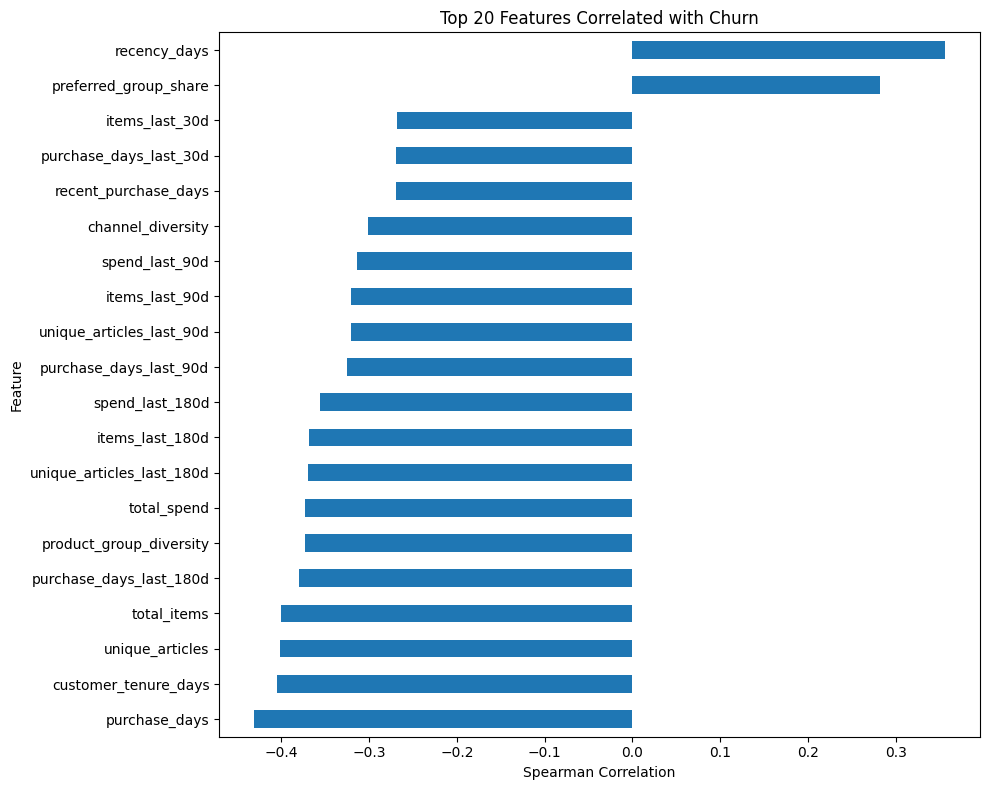

In [38]:
target = "churn_label"

numeric_cols = train_df.select_dtypes(include=np.number).columns.tolist()
numeric_cols = [
    col for col in numeric_cols
    if col not in ["customer_id"]
]

corr = train_df[numeric_cols].corr(method="spearman")

target_corr = (
    corr[target]
    .drop(target)
    .sort_values(key=lambda x: x.abs(), ascending=False)
)

display(
    target_corr.rename("correlation_with_churn").to_frame().head(20)
)

plt.figure(figsize=(10, 8))
target_corr.head(20).sort_values().plot(kind="barh")
plt.title("Top 20 Features Correlated with Churn")
plt.xlabel("Spearman Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [39]:
feature_cols = [
    col for col in numeric_cols
    if col != target
]

feature_corr = train_df[feature_cols].corr(method="spearman")

upper_triangle = feature_corr.where(
    np.triu(np.ones(feature_corr.shape), k=1).astype(bool)
)

high_corr = (
    upper_triangle.stack()
    .rename("correlation")
    .reset_index()
)

high_corr.columns = ["feature_1", "feature_2", "correlation"]

high_corr["absolute_correlation"] = high_corr["correlation"].abs()

high_corr = (
    high_corr[high_corr["absolute_correlation"] >= 0.85]
    .sort_values("absolute_correlation", ascending=False)
    .reset_index(drop=True)
)

display(high_corr)

,feature_1,feature_2,correlation,absolute_correlation
0,items_last_30d,recent_items,1.000000,1.000000
1,items_per_purchase_day,avg_basket_size,1.000000,1.000000
2,spend_last_30d,recent_spend,1.000000,1.000000
3,purchase_days_last_30d,recent_purchase_days,1.000000,1.000000
4,spend_per_purchase_day,avg_basket_spend,1.000000,1.000000
5,unique_articles_last_30d,recent_items,0.999784,0.999784
6,items_last_30d,unique_articles_last_30d,0.999784,0.999784
7,items_last_90d,unique_articles_last_90d,0.999149,0.999149
8,previous_items,previous_spend,0.998382,0.998382
9,items_last_180d,unique_articles_last_180d,0.998338,0.998338


In [41]:
duplicate_features = [
    "recent_items",
    "avg_basket_size",
    "recent_spend",
    "recent_purchase_days",
    "avg_basket_spend"
]

train_df = train_df.drop(columns=duplicate_features)

print("Updated shape:", train_df.shape)
print("Remaining duplicate columns:", train_df.columns.duplicated().sum())

Updated shape: (1016015, 42)
Remaining duplicate columns: 0


## Preparing Data for Machine Learning

In this step, we prepare the customer feature dataset for training machine learning models.

We will:
- Separate the input features (`X`) from the target label (`y`).
- Remove `customer_id` because it is an identifier, not a behavioral feature.
- Convert categorical features into numerical columns using One-Hot Encoding.
- Split the dataset into training and testing sets using an 80/20 ratio.
- Use stratified splitting to preserve the churn label distribution in both sets.
- Check the resulting dataset shapes and verify that no missing values remain.

The target variable is `churn_label`, where `1` represents customers who made no purchases during the final 90-day observation window, and `0` represents customers who made at least one purchase.

All behavioral features are intended to describe customer activity before June 25, 2020. The test set will be kept separate for evaluating model performance.

In [42]:
X = train_df.drop(columns=["churn_label", "customer_id"])
y = train_df["churn_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nTrain target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

print("\nCustomer overlap:",
      len(set(train_df.loc[X_train.index, "customer_id"]) &
          set(train_df.loc[X_test.index, "customer_id"])))

assert set(X_train.index).isdisjoint(set(X_test.index))
assert len(X_train) + len(X_test) == len(train_df)

print("\nTrain/Test split completed successfully.")

X_train: (812812, 40)
X_test: (203203, 40)

Train target distribution:
churn_label
1    71.38
0    28.62
Name: proportion, dtype: float64

Test target distribution:
churn_label
1    71.38
0    28.62
Name: proportion, dtype: float64

Customer overlap: 0

Train/Test split completed successfully.


In [43]:
categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

numerical_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Train shape:", X_train_processed.shape)
print("Test shape:", X_test_processed.shape)

Train shape: (812812, 55)
Test shape: (203203, 55)


## Baseline Model: Logistic Regression

In this step, we train a Logistic Regression classifier as our baseline model for customer churn prediction.

Logistic Regression estimates the probability that a customer belongs to the churn class based on the available customer features. It provides a simple and interpretable starting point that we can compare against more complex models.

Since the target classes are imbalanced, we use `class_weight="balanced"` to give more weight to the minority class during training.

We evaluate the model using:
- **Precision:** The proportion of customers predicted as churners who are actually labeled as churners.
- **Recall:** The proportion of actual churn-labeled customers correctly identified by the model.
- **F1-score:** The harmonic mean of precision and recall.
- **PR-AUC:** Measures performance across precision-recall thresholds and is useful for imbalanced classification problems.

We also measure ROC-AUC and accuracy for additional context. The test set is used only for evaluation, not for fitting the model.

## Logistic Regression

- **Model:** Logistic Regression
- **Encoding:** One-Hot Encoding for categorical features only.
- **Maximum iterations (`max_iter`):** 1000
- **Class weighting (`class_weight`):** `balanced`
- **Random state (`random_state`):** 42
- **Input features:** Original feature set, including `fashion_news_frequency`.
- **Data split:** Existing stratified 80/20 train-test split.
- **Evaluation metrics:** Precision, Recall, F1-score, ROC-AUC, and PR-AUC.

In [44]:
log_reg = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

log_reg.fit(X_train_processed, y_train)

y_pred = log_reg.predict(X_test_processed)
y_proba = log_reg.predict_proba(X_test_processed)[:, 1]

In [45]:
print("Logistic Regression Results")
print("=" * 40)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, y_proba):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Churned", "Churned"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Logistic Regression Results
Accuracy:  0.7273
ROC-AUC:   0.7924
PR-AUC:    0.8946

Classification Report:
              precision    recall  f1-score   support

 Not Churned     0.5173    0.7014    0.5954     58149
     Churned     0.8604    0.7377    0.7943    145054

    accuracy                         0.7273    203203
   macro avg     0.6888    0.7195    0.6949    203203
weighted avg     0.7622    0.7273    0.7374    203203

Confusion Matrix:
[[ 40784  17365]
 [ 38053 107001]]


# **Decision tree**

In [46]:
dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

dt_model.fit(X_train_processed, y_train)

dt_pred = dt_model.predict(X_test_processed)
dt_proba = dt_model.predict_proba(X_test_processed)[:, 1]

print("Decision Tree Results")
print("=" * 40)

print(f"Accuracy: {accuracy_score(y_test, dt_pred):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, dt_proba):.4f}")
print(f"PR-AUC:   {average_precision_score(y_test, dt_proba):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_pred,
    target_names=["Not Churned", "Churned"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

Decision Tree Results
Accuracy: 0.6821
ROC-AUC:  0.6131
PR-AUC:   0.7642

Classification Report:
              precision    recall  f1-score   support

 Not Churned     0.4451    0.4498    0.4474     58149
     Churned     0.7785    0.7752    0.7768    145054

    accuracy                         0.6821    203203
   macro avg     0.6118    0.6125    0.6121    203203
weighted avg     0.6831    0.6821    0.6826    203203

Confusion Matrix:
[[ 26157  31992]
 [ 32611 112443]]


In [49]:
dt = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

param_grid = {
    "max_depth": [5, 10, 15, 20],
    "min_samples_split": [2, 10, 50],
    "min_samples_leaf": [1, 10, 50],
    "criterion": ["gini", "entropy"]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_search_dt = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    refit=True
)

grid_search_dt.fit(X_train_processed, y_train)

print("Best Parameters:", grid_search_dt.best_params_)
print("Best CV ROC-AUC:", round(grid_search_dt.best_score_, 4))

best_dt = grid_search_dt.best_estimator_

Fitting 3 folds for each of 90 candidates, totalling 270 fits
Best Parameters: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 50, 'min_samples_split': 2}
Best CV ROC-AUC: 0.792


In [50]:
dt_pred = best_dt.predict(X_test_processed)
dt_proba = best_dt.predict_proba(X_test_processed)[:, 1]

print("Tuned Decision Tree Results")
print("=" * 40)

print(f"Accuracy: {accuracy_score(y_test, dt_pred):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, dt_proba):.4f}")
print(f"PR-AUC: {average_precision_score(y_test, dt_proba):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_pred,
    target_names=["Not Churned", "Churned"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

Tuned Decision Tree Results
Accuracy: 0.7178
ROC-AUC: 0.7923
PR-AUC: 0.8941

Classification Report:
              precision    recall  f1-score   support

 Not Churned     0.5048    0.7231    0.5946     58149
     Churned     0.8657    0.7156    0.7836    145054

    accuracy                         0.7178    203203
   macro avg     0.6853    0.7194    0.6891    203203
weighted avg     0.7624    0.7178    0.7295    203203

Confusion Matrix:
[[ 42049  16100]
 [ 41248 103806]]
[CV] END criterion=gini, max_depth=5, min_samples_leaf=1, min_samples_split=2; total time=  10.1s
[CV] END criterion=gini, max_depth=5, min_samples_leaf=1, min_samples_split=10; total time=   9.9s
[CV] END criterion=gini, max_depth=5, min_samples_leaf=10, min_samples_split=2; total time=  10.0s
[CV] END criterion=gini, max_depth=5, min_samples_leaf=10, min_samples_split=10; total time=   9.8s
[CV] END criterion=gini, max_depth=5, min_samples_leaf=50, min_samples_split=2; total time=   9.9s
[CV] END criterion=gini, 

# **ٌRandom forest**

In [47]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)
rf_proba = rf_model.predict_proba(X_test_processed)[:, 1]

In [48]:
print("Random Forest Results")
print("=" * 40)

print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, rf_proba):.4f}")
print(f"PR-AUC:   {average_precision_score(y_test, rf_proba):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Not Churned", "Churned"],
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Results
Accuracy: 0.7626
ROC-AUC:  0.7743
PR-AUC:   0.8806

Classification Report:
              precision    recall  f1-score   support

 Not Churned     0.6309    0.4105    0.4974     58149
     Churned     0.7927    0.9037    0.8446    145054

    accuracy                         0.7626    203203
   macro avg     0.7118    0.6571    0.6710    203203
weighted avg     0.7464    0.7626    0.7452    203203

Confusion Matrix:
[[ 23872  34277]
 [ 13964 131090]]


In [59]:
SAVE_DIR = Path("/kaggle/working/random_forest_artifacts")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

model = rf_model

# Predictions
X_eval = X_test_processed
y_pred = model.predict(X_eval)
y_prob = model.predict_proba(X_eval)[:, 1]

# Save ONE complete inference pipeline
full_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])

joblib.dump(
    full_pipeline,
    SAVE_DIR / "churn_pipeline.joblib",
    compress=3
)

# Feature names
feature_names = X_train.columns.tolist()

with open(SAVE_DIR / "feature_names.json", "w", encoding="utf-8") as f:
    json.dump(feature_names, f, indent=2, ensure_ascii=False)

feature_schema = pd.DataFrame({
    "feature_name": feature_names,
    "data_type": [str(X_train[col].dtype) for col in feature_names]
})

feature_schema.to_csv(
    SAVE_DIR / "feature_schema.csv",
    index=False
)

# Model parameters
with open(SAVE_DIR / "model_parameters.json", "w", encoding="utf-8") as f:
    json.dump(model.get_params(), f, indent=2, default=str)

# Evaluation metrics
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

metrics = {
    "model_name": "Random Forest",
    "accuracy": float(accuracy_score(y_test, y_pred)),
    "roc_auc": float(roc_auc_score(y_test, y_prob)),
    "pr_auc": float(average_precision_score(y_test, y_prob)),
    "confusion_matrix": cm.tolist(),
    "confusion_matrix_labels": ["Not Churned", "Churned"],
    "true_negatives": int(cm[0, 0]),
    "false_positives": int(cm[0, 1]),
    "false_negatives": int(cm[1, 0]),
    "true_positives": int(cm[1, 1]),
    "classification_report": classification_report(
        y_test,
        y_pred,
        output_dict=True,
        zero_division=0
    )
}

with open(SAVE_DIR / "evaluation_metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

# Test predictions
predictions = pd.DataFrame({
    "actual_label": np.asarray(y_test),
    "predicted_label": np.asarray(y_pred),
    "predicted_probability": np.asarray(y_prob)
})

if "customer_id" in train_df.columns:
    predictions.insert(
        0,
        "customer_id",
        train_df.loc[X_test.index, "customer_id"].to_numpy()
    )

predictions.to_csv(
    SAVE_DIR / "test_predictions.csv",
    index=False
)

# Data split information
split_data = {
    "random_state": 42,
    "test_size": float(len(X_test) / (len(X_train) + len(X_test))),
    "stratified": True,
    "train_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "train_class_counts": {
        str(k): int(v) for k, v in y_train.value_counts().items()
    },
    "test_class_counts": {
        str(k): int(v) for k, v in y_test.value_counts().items()
    }
}

with open(SAVE_DIR / "data_split_info.json", "w", encoding="utf-8") as f:
    json.dump(split_data, f, indent=2)

# Package versions
requirements = [
    f"python=={sys.version_info.major}.{sys.version_info.minor}.{sys.version_info.micro}",
    f"scikit-learn=={sklearn.__version__}",
    f"joblib=={joblib.__version__}",
    f"numpy=={np.__version__}",
    f"pandas=={pd.__version__}"
]

(SAVE_DIR / "requirements.txt").write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

# Report file sizes
print("Saved directory:", SAVE_DIR.resolve())
print("\nSaved files:")

for file in sorted(SAVE_DIR.iterdir()):
    if file.is_file():
        size_mb = file.stat().st_size / (1024 ** 2)
        print(f"{file.name}: {size_mb:.2f} MB")

print(f"\nTotal size: {sum(f.stat().st_size for f in SAVE_DIR.iterdir() if f.is_file()) / (1024 ** 3):.2f} GB")

print("\nEvaluation metrics:")
print(json.dumps(
    {k: v for k, v in metrics.items()
     if k != "classification_report"},
    indent=2
))


Saved directory: /kaggle/working/random_forest_artifacts

Saved files:
churn_pipeline.joblib: 1119.66 MB
data_split_info.json: 0.00 MB
evaluation_metrics.json: 0.00 MB
feature_names.json: 0.00 MB
feature_schema.csv: 0.00 MB
model_parameters.json: 0.00 MB
preprocessor.joblib: 0.00 MB
random_forest_model.joblib: 1119.64 MB
requirements.txt: 0.00 MB
test_predictions.csv: 14.51 MB

Total size: 2.20 GB

Evaluation metrics:
{
  "model_name": "Random Forest",
  "accuracy": 0.7625970089024277,
  "roc_auc": 0.7742808982824114,
  "pr_auc": 0.8805573669718129,
  "confusion_matrix": [
    [
      23872,
      34277
    ],
    [
      13964,
      131090
    ]
  ],
  "confusion_matrix_labels": [
    "Not Churned",
    "Churned"
  ],
  "true_negatives": 23872,
  "false_positives": 34277,
  "false_negatives": 13964,
  "true_positives": 131090
}
